# Phase 6: PCA and Regime Discovery

**Project:** Regime-Aware Adaptive Trading & Risk Management System (DS605)
**Inputs:** `data/processed/features.csv` (Phase 5), plus `clean.csv` and `macro.csv` for the Nifty close and the cash rate that later phases need
**Outputs:** `data/processed/regimes.csv`, fitted `scaler`, `pca`, `kmeans` in `models/`, `regime_meta.json`, figures in `reports/figures/regime_*.png`

---

### What this phase does and the rules it follows

Phase 6 groups trading days into market regimes with no target variable: **StandardScaler → PCA → K-Means** (cross-checked with **Ward hierarchical clustering**). Regime names come only from the cluster statistics.

| Rule (from `Project_Outline.md`) | How it is enforced here |
|---|---|
| Fit scaler, PCA and K-Means on **2008-2017 only** | Every `.fit()` call uses `X_train` / `Z_train` only; test data only goes through `.transform()` / `.predict()` |
| Test = 2018 to Oct 2026 assigned with `KMeans.predict` | Section 10 |
| k = 2 to 5, choose by silhouette **and** minimum cluster size **and** interpretability | Sections 6 to 8 |
| Name regimes from statistics, never in advance | Section 9: names are assigned only after the profile table, with assertions that check each name against the numbers |
| No look-ahead | Features already use data up to the close of day *t* (Phase 5). The regime label for day *t* is therefore known at the close of *t*; **Phase 8/9 must shift it by one day** before using it for a forecast or an exposure decision |

Random seed: `42` everywhere.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

SEED = 42
TRAIN_END = "2017-12-31"          # fixed in Project_Outline.md Section 3
EXPLAINED_VAR_TARGET = 0.85       # lower end of the 85-90% band, justified in Section 5
K_RANGE = range(2, 6)
N_INIT = 50                       # K-Means restarts, so the result does not depend on one lucky start

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS, FIG_DIR = ROOT / "data" / "processed", ROOT / "models", ROOT / "reports" / "figures"
for d in (MODELS, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"regime_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Loading and inspecting the Phase 5 outputs

**What:** load `features.csv` and check dates, missing values, duplicates, types and distributions before any modelling.
**Why:** PCA and K-Means silently accept bad input (NaNs raise errors, but duplicated dates or an unsorted index would not), and a wrong date order would quietly break the chronological split.
**This is unsupervised:** there is no target column. `split` is only a train/test label written in Phase 5, and it is not a feature.

In [2]:
features = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
with open(PROC / "feature_meta.json") as f:
    feature_meta = json.load(f)

FEATURE_COLS = [c for c in features.columns if c != "split"]
print("Shape            :", features.shape, f"({len(FEATURE_COLS)} features + 'split')")
print("Date range       :", features.index.min().date(), "to", features.index.max().date())
print("Missing values   :", int(features[FEATURE_COLS].isna().sum().sum()))
print("Duplicate dates  :", int(features.index.duplicated().sum()))
print("Sorted ascending :", features.index.is_monotonic_increasing)
print("Non-float cols   :", [c for c in FEATURE_COLS if features[c].dtype != float])
print("Infinite values  :", int(np.isinf(features[FEATURE_COLS]).sum().sum()))
print("Split column     :", features["split"].value_counts().to_dict())

assert features.index.is_monotonic_increasing and features.index.is_unique
assert features[FEATURE_COLS].isna().sum().sum() == 0

Shape            : (4509, 22) (21 features + 'split')
Date range       : 2008-06-09 to 2026-10-27
Missing values   : 0
Duplicate dates  : 0
Sorted ascending : True
Non-float cols   : []
Infinite values  : 0
Split column     : {'train': 2336, 'test': 2173}


In [3]:
groups = pd.read_csv(ROOT / "reports" / "feature_dictionary.csv").set_index("feature")["group"]
summary = features[FEATURE_COLS].describe().T[["mean", "std", "min", "50%", "max"]]
summary["skew"] = features[FEATURE_COLS].skew()
summary.insert(0, "group", groups.reindex(summary.index))
display(summary.round(3))

,group,mean,std,min,50%,max,skew
nifty_ret_1d,indian,0.000,0.012,-0.139,0.001,0.163,-0.257
nifty_ret_5d,indian,0.002,0.028,-0.213,0.003,0.196,-0.479
nifty_ret_21d,indian,0.007,0.060,-0.500,0.010,0.303,-1.220
nifty_vol_10d,indian,0.162,0.111,0.031,0.134,1.081,3.558
nifty_vol_21d,indian,0.166,0.105,0.051,0.140,0.895,3.282
nifty_vol_63d,indian,0.172,0.096,0.074,0.147,0.624,2.543
nifty_drawdown,indian,-0.096,0.109,-0.599,-0.063,0.000,-2.213
nifty_ma_gap_21d,indian,0.003,0.033,-0.310,0.006,0.194,-1.562
nifty_ma_gap_63d,indian,0.010,0.059,-0.469,0.015,0.327,-1.349
nifty_skew_63d,indian,-0.087,0.645,-2.944,-0.076,2.733,0.456


**Reading the table (before any modelling):**
- The 21 features are on very different scales: `vix_level` is in the tens, `nifty_ret_1d` is about 0.01, `us10y_level` is in percent and `repo_change_63d` is in percentage points. This is the first reason PCA cannot be run on raw features (Section 4).
- `nifty_kurt_63d` and `vix_level` are strongly right-skewed (rare crisis spikes). `nifty_vol_*` and `nifty_drawdown` are skewed too. These tails are exactly the information that distinguishes regimes, so we do **not** winsorise or log-transform them. The one scaler decision this affects is discussed in Section 4.
- Two features are different in kind from the rest: `us10y_level` is a *level* with a slow multi-year trend, and `repo_change_63d` is a step-shaped policy variable that is exactly zero about half the time. Both are kept because they are in the agreed Phase 5 feature set, but Section 8 tests whether the regimes depend on them.

## 3. Chronological train-test split

**What:** train = 2008-06-09 to 2017-12-29, test = 2018-01-02 to 2026-10-27, split by date.

**Why chronological?** A regime label is only useful if it can be produced *without knowing the future*. In deployment, the scaler, PCA and cluster centres exist before tomorrow's data arrives. A chronological split reproduces that situation: everything is learned from the past and evaluated on a later period. It also keeps the test period as a genuine out-of-sample stress test (it contains 2020 and 2022, which the model never saw).

**Why not a random split?** Financial features here are rolling windows (21, 63 days), so neighbouring days share most of their inputs. A random split would put day *t* in train and day *t+1* in test, with nearly identical feature vectors. The test score would measure memory of the neighbours, and the scaler, PCA and centres would have been fitted with information from the test period. Volatility clustering (Phase 3 EDA) makes this worse, because a crisis is a block of consecutive similar days, not independent samples.

**Known consequence of the fixed split:** the 2008-09 crisis is in the training window and 2020 is in the test window, so the cluster centres are learned from the 2008-era crisis.

In [4]:
train = features.loc[:TRAIN_END, FEATURE_COLS]
test  = features.loc[pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1):, FEATURE_COLS]

# must agree with the split label written in Phase 5
assert (features.loc[train.index, "split"] == "train").all() and (features.loc[test.index, "split"] == "test").all()
assert train.index.max() < test.index.min() and len(train) + len(test) == len(features)

split_table = pd.DataFrame({
    "rows": [len(train), len(test)],
    "start": [train.index.min().date(), test.index.min().date()],
    "end": [train.index.max().date(), test.index.max().date()],
    "mean India VIX": [train["vix_level"].mean().round(1), test["vix_level"].mean().round(1)],
    "days VIX > 25 (%)": [round((train["vix_level"] > 25).mean() * 100, 1), round((test["vix_level"] > 25).mean() * 100, 1)],
    "days drawdown < -20% (%)": [round((train["nifty_drawdown"] < -0.20).mean() * 100, 1), round((test["nifty_drawdown"] < -0.20).mean() * 100, 1)],
}, index=["train", "test"])
display(split_table)

,rows,start,end,mean India VIX,days VIX > 25 (%),days drawdown < -20% (%)
train,2336,2008-06-09,2017-12-29,22.0,25.6,20.7
test,2173,2018-01-02,2026-10-27,16.9,6.0,2.4


**Interpretation:** the split matches the Phase 5 label exactly. The two periods are very different in stress level: **25.6% of training days have VIX above 25, against 6.0% in the test period**, and 20.7% of training days sit more than 20% below the peak, against 2.4% in test. This has two consequences that the rest of the notebook keeps in view. First, the model learns what stress looks like from a stress-heavy period, which is good for defining the stressed regimes. Second, the test period will contain far fewer stressed days, so any regime that is rare in training will be very rare in test (Section 10).

## 4. Standardization

**What:** fit `StandardScaler` on the training features only, then transform train and test with the *same* fitted object (z = (x - mean_train) / std_train).

**Why it is necessary before PCA:** PCA finds the directions of largest *variance*. On raw data, `vix_level` (variance of about 100) would dominate `nifty_ret_1d` (variance of about 0.0002) simply because of its units, and PC1 would just be "VIX". Standardising gives every feature unit variance, so PCA works on the correlation structure, which is what we want.

**Why `StandardScaler` and not the alternatives:**

| Scaler | Why not here |
|---|---|
| `MinMaxScaler` | Uses the min and max, which are set by one or two crisis days (e.g. VIX 85). It compresses all normal days into a tiny range and the test period could fall outside [0, 1]. |
| `RobustScaler` (median/IQR) | Designed to *reduce* the influence of outliers. Here the outliers are the signal: a 2008 or 2020 day is exactly what the stressed regime should be built from. Shrinking them would weaken the separation between calm and stressed days. |
| `StandardScaler` | Keeps relative distances, gives the mean and variance PCA expects, and keeps crisis days far from calm days. Its weakness is that outliers inflate the std. With a 2008 crisis inside the training window, std is a little larger for the vol/VIX features, which is acceptable and is fixed once in training. |

**No leakage:** mean and std come from 2,336 training rows only. Test rows use those numbers even when their values look unusual.

In [5]:
scaler = StandardScaler().fit(train)                      # TRAIN ONLY
Z_train = pd.DataFrame(scaler.transform(train), index=train.index, columns=FEATURE_COLS)
Z_test  = pd.DataFrame(scaler.transform(test),  index=test.index,  columns=FEATURE_COLS)

print("Train: mean of z (max abs) =", round(float(Z_train.mean().abs().max()), 10),
      "| std range =", round(float(Z_train.std(ddof=0).min()), 3), "to", round(float(Z_train.std(ddof=0).max()), 3))
assert np.allclose(Z_train.mean(), 0, atol=1e-9) and np.allclose(Z_train.std(ddof=0), 1)
assert (Z_train.index == train.index).all() and (Z_test.index == test.index).all()

drift = pd.DataFrame({"test mean z": Z_test.mean(), "test max |z|": Z_test.abs().max()})
print()
print("Features where the test period is most shifted from the training distribution:")
display(drift.reindex(drift["test mean z"].abs().sort_values(ascending=False).index).head(6).round(2))

Train: mean of z (max abs) = 0.0 | std range = 1.0 to 1.0

Features where the test period is most shifted from the training distribution:


,test mean z,test max |z|
us10y_level,0.70,4.16
nifty_drawdown,0.60,1.90
vix_level,-0.51,6.16
nifty_vol_63d,-0.42,3.60
nifty_vol_21d,-0.38,6.24
nifty_vol_10d,-0.36,7.46


**Interpretation:** the training z-scores have mean 0 and std 1 by construction. The check that matters is the test period: it has **no leakage in how it is scaled, and it shows real distribution shift**. `us10y_level` is shifted by about +0.7 training standard deviations and reaches 5.3% against a training maximum of 4.3%; `nifty_drawdown` is shifted by +0.6 (the test period is shallower); `vix_level` and the volatility features are shifted down. A few extreme test days (e.g. Brent and 1-day returns, |z| above 8) are outside anything seen in training. We keep the scaler fixed anyway, as required by the no-leakage rule. Section 10 checks how far test days are from their assigned centres.

## 5. PCA and explained variance analysis

**What PCA does:** it rotates the 21 standardised features into new, uncorrelated axes (principal components) ordered by how much variance they capture. Each component is a weighted combination of the original features (the loadings), so PC1 might be "overall stress" and PC2 "trend/momentum". Keeping the first *m* components keeps most of the variance while removing redundancy.

**Why it is useful here:**
- Phase 5 already found correlated groups (10/21/63-day volatility, VIX, drawdown, stock correlation), so many of the 21 features measure the same thing. In raw 21-D space this stress information would be counted several times in the K-Means Euclidean distance, giving it more weight than momentum or macro features. PCA collapses it into one axis first.
- K-Means works on Euclidean distance, which becomes less informative in more dimensions and is sensitive to redundant features. Fewer, uncorrelated dimensions give more stable clusters.
- It also gives 2-D views of the regimes (PC1 vs PC2) for the report and the app.

**Threshold:** the outline says 85 to 90%. We use **the smallest number of components that reaches 85%**. Reasons: components beyond that each add under 3% of variance and mostly encode idiosyncratic noise (e.g. single-day return spikes); K-Means on 8, 9, 10 or 11 components gives almost the same partition (checked below); and a smaller *m* keeps more of the clustering weight on the broad market-state axes. We do not need 90% for reconstruction accuracy, because the goal is clustering, not compression.

In [6]:
pca_full = PCA(random_state=SEED).fit(Z_train)            # TRAIN ONLY: used to inspect the whole spectrum
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
N_COMP = int(np.argmax(cum >= EXPLAINED_VAR_TARGET) + 1)

pca_table = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))],
                          "explained variance ratio": evr.round(4),
                          "cumulative": cum.round(4)}).set_index("PC")
display(pca_table.head(12))
print(f"Components needed for 85%: {N_COMP}  (cumulative = {cum[N_COMP-1]:.4f})")
print(f"Components needed for 90%: {int(np.argmax(cum >= 0.90) + 1)}  (cumulative = {cum[int(np.argmax(cum >= 0.90))]:.4f})")

,explained variance ratio,cumulative
PC,,
PC1,0.2960,0.2960
PC2,0.1920,0.4880
PC3,0.0775,0.5654
PC4,0.0645,0.6299
PC5,0.0586,0.6885
PC6,0.0501,0.7386
PC7,0.0449,0.7835
PC8,0.0390,0.8225
PC9,0.0334,0.8559


Components needed for 85%: 9  (cumulative = 0.8559)
Components needed for 90%: 11  (cumulative = 0.9111)


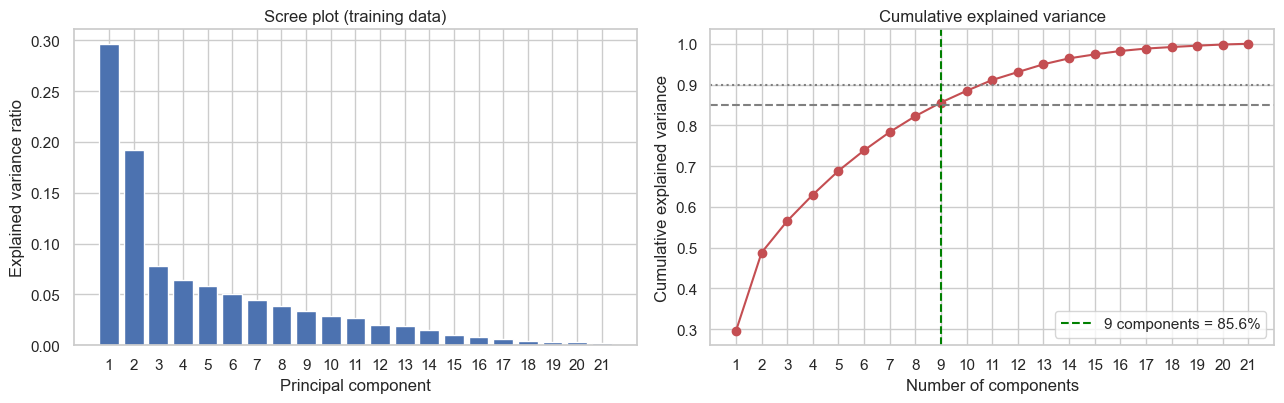

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
idx = np.arange(1, len(evr) + 1)
ax[0].bar(idx, evr, color="#4c72b0")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio"); ax[0].set_title("Scree plot (training data)")
ax[0].set_xticks(idx)
ax[1].plot(idx, cum, marker="o", color="#c44e52")
ax[1].axhline(0.85, ls="--", color="grey"); ax[1].axhline(0.90, ls=":", color="grey")
ax[1].axvline(N_COMP, ls="--", color="green", label=f"{N_COMP} components = {cum[N_COMP-1]:.1%}")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xticks(idx); ax[1].legend(loc="lower right")
save_fig("pca_variance")

Retained 9 components, explained variance = 85.59%


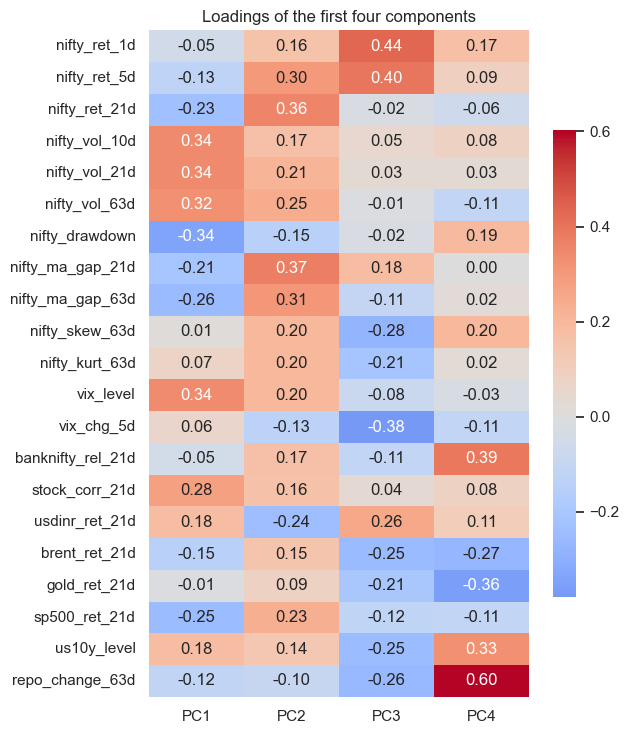

In [8]:
pca = PCA(n_components=N_COMP, random_state=SEED).fit(Z_train)     # the PCA used from here on: TRAIN ONLY
X_train = pd.DataFrame(pca.transform(Z_train), index=train.index, columns=[f"PC{i+1}" for i in range(N_COMP)])
X_test  = pd.DataFrame(pca.transform(Z_test),  index=test.index,  columns=X_train.columns)
assert X_train.shape == (len(train), N_COMP) and X_test.shape == (len(test), N_COMP)
assert np.allclose(pca.explained_variance_ratio_, evr[:N_COMP])
print(f"Retained {N_COMP} components, explained variance = {pca.explained_variance_ratio_.sum():.2%}")

loadings = pd.DataFrame(pca.components_[:4].T, index=FEATURE_COLS, columns=["PC1", "PC2", "PC3", "PC4"])
plt.figure(figsize=(6.5, 7.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": .7})
plt.title("Loadings of the first four components")
save_fig("pca_loadings")

**Interpretation:**
- **9 components keep 85.6% of the variance** (10 would keep 88.5%, 11 would keep 91.1%). The first two components carry 48.8% by themselves, and no component after PC2 has more than 8%. That is a typical shape for correlated financial features: a few broad market-state axes followed by many weak ones.
- **PC1 (29.6%) is a stress axis.** Positive loadings on all three volatility windows, VIX, stock correlation and USD/INR; negative on drawdown, 21/63-day returns and the S&P 500 return. High PC1 = high volatility, deep drawdown, stocks moving together.
- **PC2 (19.2%) is a trend/momentum axis.** It loads on the 21 and 63-day returns and moving-average gaps. It is mostly independent of volatility, which is what lets K-Means separate a stressed *fall* from a stressed *rebound* later.
- **PC4 is dominated by `repo_change_63d` (0.60 loading).** This is a policy-rate variable with a step shape. We flag it and test its influence on clusters in Section 8; it does not drive PC1 or PC2.

In [9]:
rows = []
for m in (8, 9, 10, 11):
    p_m = PCA(n_components=m, random_state=SEED).fit(Z_train)
    X_m = p_m.transform(Z_train)
    for k in K_RANGE:
        km_m = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_m)
        rows.append({"components": m, "variance kept": round(p_m.explained_variance_ratio_.sum(), 3), "k": k,
                     "silhouette": round(silhouette_score(X_m, km_m.labels_), 3), "min cluster": int(np.bincount(km_m.labels_).min())})
sens = pd.DataFrame(rows)
display(sens.pivot(index="k", columns="components", values="silhouette"))
display(sens.pivot(index="k", columns="components", values="min cluster"))

components,8,9,10,11
k,,,,
2,0.504,0.493,0.490,0.482
3,0.464,0.456,0.449,0.427
4,0.246,0.234,0.231,0.219
5,0.261,0.249,0.245,0.236


components,8,9,10,11
k,,,,
2,308,308,299,299
3,135,135,134,138
4,107,107,104,107
5,35,35,35,35


**Interpretation:** the silhouette scores and minimum cluster sizes barely change between 8 and 11 components (for example k=3 stays between 0.43 and 0.46, k=4 between 0.22 and 0.25). The choice of 9 components therefore does not drive the conclusions, and the 85% end of the band is justified by parsimony rather than by a hand-picked result.

## 6. K-Means clustering for k = 2 to 5

**How K-Means works:** choose k centres, assign every point to its nearest centre (Euclidean distance), recompute each centre as the mean of its points, and repeat until assignments stop changing. It minimises within-cluster squared distance. We use `n_init=50` restarts and keep the best, because a single run can end in a poor local optimum.

**Why it is appropriate here:**
- The input is a compact, continuous, standardised and decorrelated space (PCA output), which is where Euclidean K-Means is well behaved.
- It returns a hard label per day and centroids, so **a new day can be assigned with `.predict()`**. That is exactly what Phase 6.5 and the deployed app need: a fixed rule from training that is applied to later data.
- The number of clusters is explicit, which suits the project goal of a small interpretable set of regimes.

**Why not DBSCAN or Gaussian Mixture Models as the primary method:**
- *DBSCAN* has no natural way to label new days beyond the training set, and its density threshold would treat the rare crisis days as noise, i.e. it would throw away the stressed days we most want to label. Market states are also not separated by clear density gaps: they form a continuum.
- *GMM* is the better statistical model when clusters have different shapes or when soft probabilities are wanted. It is listed in the outline as future work. It adds covariance parameters (with 9 dimensions and some clusters of ~100 points this is easy to overfit) and, more importantly, the outline fixes PCA + K-Means with hierarchical cross-check.

**Silhouette score:** for each point, (b - a) / max(a, b), where a is the mean distance to its own cluster and b the mean distance to the nearest other cluster. It ranges from -1 to 1, and higher means tighter and better-separated clusters.
**Limitations:** it favours compact, similar-sized, convex clusters and so tends to prefer small k; it measures geometry only and says nothing about financial meaning; and it can be high for a split that just isolates a few outliers. **The highest silhouette is therefore not automatically the best solution**: k=2 will tend to score well simply because "calm vs everything stressed" is the coarsest split, while being the least useful for a risk rule.

For each k we also record cluster sizes, the smallest cluster as a share of training days, the mean India VIX per cluster (as a quick interpretability read) and two stability measures: agreement (Adjusted Rand Index) between the reference fit and 50 bootstrap refits, and between the reference fit and 20 single-start refits with different seeds.

In [10]:
def bootstrap_stability(X, labels_ref, k, n_boot=50, seed=0):
    """ARI between the reference clustering and K-Means refitted on bootstrap resamples (predicted back on all rows)."""
    rng, aris = np.random.default_rng(seed), []
    for b in range(n_boot):
        idx = np.sort(rng.choice(len(X), len(X), replace=True))
        kb = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(labels_ref, kb.predict(X)))
    return float(np.mean(aris))

def seed_stability(X, labels_ref, k, n_seeds=20):
    return float(np.mean([adjusted_rand_score(labels_ref, KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).labels_) for s in range(n_seeds)]))

Xtr = X_train.to_numpy()
km_models, km_rows = {}, []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Xtr)       # TRAIN ONLY
    km_models[k] = km
    sizes = np.bincount(km.labels_, minlength=k)
    vix_by = train.assign(c=km.labels_).groupby("c")["vix_level"].mean()
    sil_by = pd.Series(silhouette_samples(Xtr, km.labels_)).groupby(km.labels_).mean()
    km_rows.append({
        "k": k,
        "Silhouette Score": round(silhouette_score(Xtr, km.labels_), 3),
        "Cluster Sizes": "/".join(str(s) for s in sizes[np.argsort(vix_by.values)]),
        "Minimum Cluster Size": int(sizes.min()),
        "Min size (% of train)": round(sizes.min() / len(Xtr) * 100, 1),
        "Mean VIX by cluster": "/".join(f"{v:.0f}" for v in np.sort(vix_by.values)),
        "Lowest cluster silhouette": round(sil_by.min(), 3),
        "Bootstrap ARI": round(bootstrap_stability(Xtr, km.labels_, k), 3),
        "Seed ARI (1 start)": round(seed_stability(Xtr, km.labels_, k), 3),
    })
km_table = pd.DataFrame(km_rows).set_index("k")
km_table["Observations"] = ""
display(km_table.drop(columns="Observations"))

,Silhouette Score,Cluster Sizes,Minimum Cluster Size,Min size (% of train),Mean VIX by cluster,Lowest cluster silhouette,Bootstrap ARI,Seed ARI (1 start)
k,,,,,,,,
2,0.493,2028/308,308,13.2,19/43,-0.035,0.930,1.000
3,0.456,1957/244/135,135,5.8,19/38/43,0.025,0.790,0.808
4,0.234,1481/635/113/107,107,4.6,17/25/43/49,0.078,0.901,0.752
5,0.249,1495/629/63/114/35,35,1.5,17/25/42/45/58,0.074,0.752,0.661


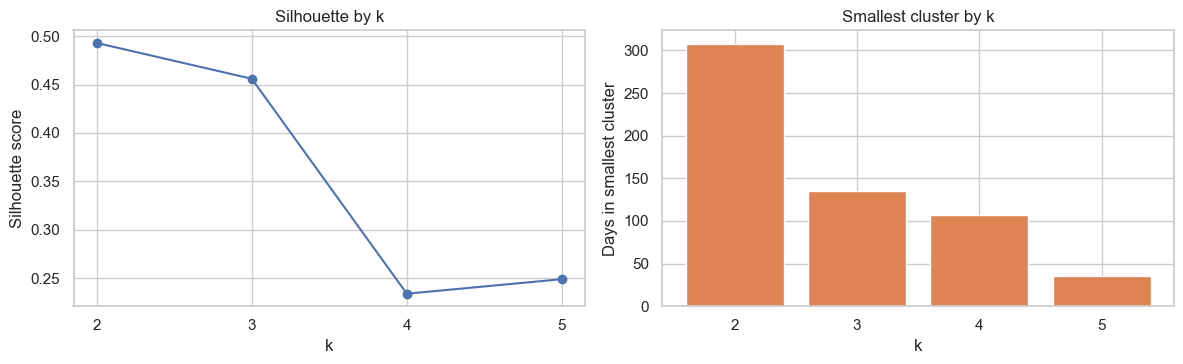

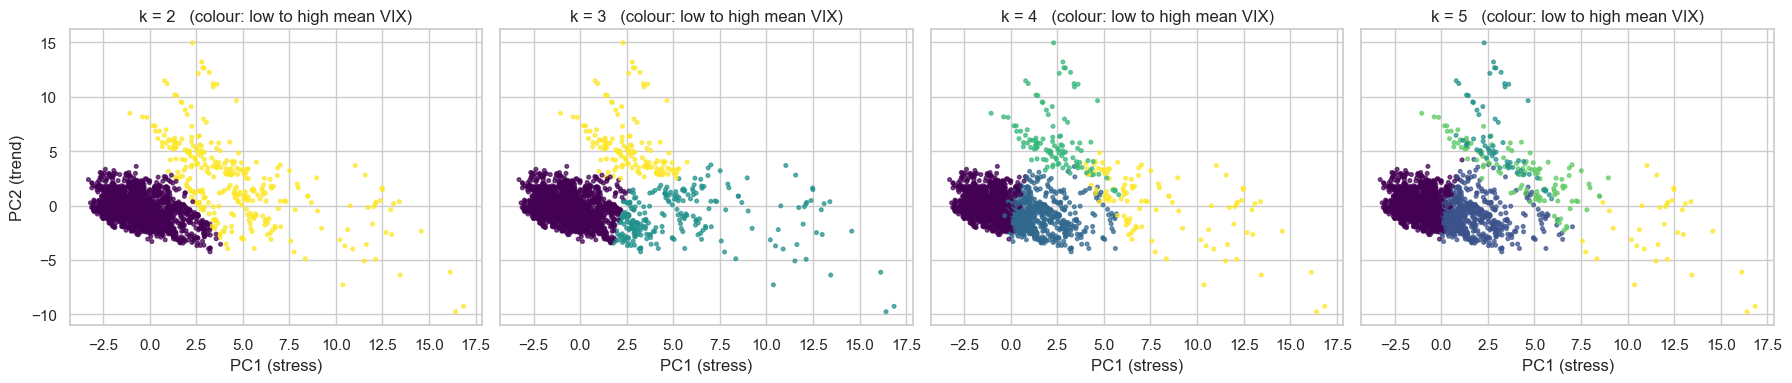

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(km_table.index, km_table["Silhouette Score"], marker="o", color="#4c72b0")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Silhouette score"); ax[0].set_title("Silhouette by k"); ax[0].set_xticks(list(K_RANGE))
ax[1].bar(km_table.index, km_table["Minimum Cluster Size"], color="#dd8452")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Days in smallest cluster"); ax[1].set_title("Smallest cluster by k"); ax[1].set_xticks(list(K_RANGE))
save_fig("kmeans_k_comparison")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for ax_, k in zip(axes, K_RANGE):
    order = np.argsort(train.assign(c=km_models[k].labels_).groupby("c")["vix_level"].mean().values)
    rank = {c: r for r, c in enumerate(order)}
    lab = np.vectorize(rank.get)(km_models[k].labels_)
    ax_.scatter(X_train["PC1"], X_train["PC2"], c=lab, cmap="viridis", s=7, alpha=.7)
    ax_.set_title(f"k = {k}   (colour: low to high mean VIX)"); ax_.set_xlabel("PC1 (stress)")
axes[0].set_ylabel("PC2 (trend)")
save_fig("kmeans_pc_scatter")

**How to read these results.** (1) **k = 2 has the highest silhouette (0.49)** and k = 3 is close (0.46); **the score then falls sharply to 0.23 at k = 4 and 0.25 at k = 5**. This cliff is the main evidence from the geometry: two and three groups are real structure; a fourth group is carved out of a continuum. (2) The smallest cluster is 35 days at k = 5 (1.5% of training days) and 107-113 days at k = 4. (3) Within k = 4 the extra cluster is a "middle" band (mean VIX about 25) that sits between calm and stressed days with no gap, which is why silhouette collapses. (4) Bootstrap stability is 0.93 at k = 2, 0.79 at k = 3, **0.90 at k = 4** and 0.75 at k = 5. k = 4 is therefore *not* unstable under resampling; its problem is separation (silhouette 0.23), and it is sensitive to the random start when only one start is used (seed ARI 0.75), which `n_init=50` removes.

The scatter plot shows why: the calm days form one dense cloud (lower PC1), and the stressed days are a long diffuse arm at high PC1. Going from k = 3 to k = 4 and 5 mostly cuts the dense calm cloud and the arm into slices.

## 7. Hierarchical clustering with Ward's linkage (cross-check)

**How it works:** start with every day as its own cluster and repeatedly merge the two clusters whose union increases total within-cluster variance the least (Ward's criterion). The result is a full tree (dendrogram). Cutting the tree at any height gives a clustering with any number of groups, and the **height of each merge** shows how different the two merged groups were.

**Why Ward:** it uses the same objective as K-Means (minimise within-cluster variance) on the same Euclidean PCA space, so the two methods are directly comparable. Single linkage chains through the continuum of market days into one giant cluster; complete and average linkage are driven by distances to extreme days, and the crisis days are exactly the extreme days. Ward tends to produce compact, similar-sized groups.

**Why it is a useful cross-check:** it is deterministic (no random starts), does not need k in advance, and its merge heights give an independent view of how many groups the data supports. If Ward and K-Means disagree wildly, the K-Means regimes are probably an artefact of initialisation.

**Computational limit:** Ward needs the full pairwise distance matrix, O(n^2) memory and roughly O(n^2) to O(n^2 log n) time. For 2,336 training days this is about 2.7 million distances and runs in seconds, so **the clustering below uses the full training set; nothing is sampled.** (At this project's full length of 4,509 days it would still be fine; it becomes impractical in the tens of thousands.) The only simplification is in the *plot*: a dendrogram with 2,336 leaves is unreadable, so we draw only the last 30 merges (`truncate_mode="lastp"`), which is a display choice that does not change the clustering.

Ward is also a one-off: it has no `predict()`, so it **cannot** assign test days. This is why it is a cross-check, not the primary model.

Linkage matrix: (2335, 4) | last 8 merge heights: [ 42.8  47.5  49.8  59.9  73.3  81.4  82.5 131.6]


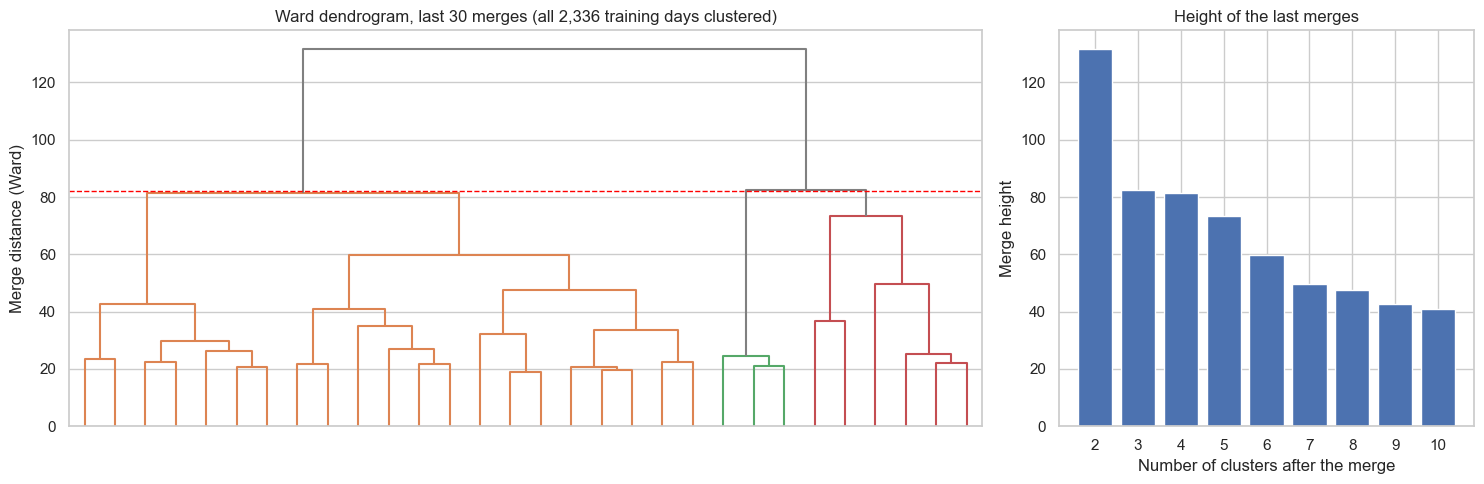

In [12]:
W = linkage(Xtr, method="ward")                           # full training set, no sampling
print("Linkage matrix:", W.shape, "| last 8 merge heights:", np.round(W[-8:, 2], 1))

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})
thr = (W[-3, 2] + W[-2, 2]) / 2                           # colour at the 3-cluster cut
dendrogram(W, truncate_mode="lastp", p=30, ax=ax[0], color_threshold=thr, no_labels=True, above_threshold_color="grey")
ax[0].axhline(thr, ls="--", color="red", lw=1); ax[0].set_title("Ward dendrogram, last 30 merges (all 2,336 training days clustered)")
ax[0].set_ylabel("Merge distance (Ward)")
heights = W[-9:, 2][::-1]
ax[1].bar(range(2, 2 + len(heights)), heights, color="#4c72b0")
ax[1].set_xlabel("Number of clusters after the merge"); ax[1].set_ylabel("Merge height")
ax[1].set_title("Height of the last merges"); ax[1].set_xticks(range(2, 2 + len(heights)))
save_fig("ward_dendrogram")

In [13]:
rows = []
for k in K_RANGE:
    hc = fcluster(W, k, criterion="maxclust") - 1
    rows.append({"k": k, "Ward sizes (large to small)": "/".join(str(s) for s in sorted(np.bincount(hc), reverse=True)),
                 "K-Means sizes (large to small)": "/".join(str(s) for s in sorted(np.bincount(km_models[k].labels_), reverse=True)),
                 "ARI (Ward vs K-Means)": round(adjusted_rand_score(hc, km_models[k].labels_), 3),
                 "Ward silhouette": round(silhouette_score(Xtr, hc), 3)})
ward_table = pd.DataFrame(rows).set_index("k")
display(ward_table)

hc3 = fcluster(W, 3, criterion="maxclust") - 1
km3_order = train.assign(c=km_models[3].labels_).groupby("c")["vix_level"].mean().sort_values().index
print("\nK-Means (rows, low to high VIX) vs Ward (columns), k = 3:")
display(pd.crosstab(pd.Series(km_models[3].labels_, name="K-Means").map({c: i for i, c in enumerate(km3_order)}), pd.Series(hc3, name="Ward")))

,Ward sizes (large to small),K-Means sizes (large to small),ARI (Ward vs K-Means),Ward silhouette
k,,,,
2,2131/205,2028/308,0.733,0.540
3,2131/175/30,1957/244/135,0.619,0.521
4,1138/993/175/30,1481/635/113/107,0.484,0.152
5,1138/993/112/63/30,1495/629/114/63/35,0.494,0.166



K-Means (rows, low to high VIX) vs Ward (columns), k = 3:


Ward,0,1,2
K-Means,,,
0,1957,0,0
1,155,30,59
2,19,0,116


**Interpretation:**
- **The dendrogram has one dominant split.** The last merge (joining two groups into one) is at height 131.6, against 82.5 for the one before it and 81.4, 73.3 and 59.9 after that. The tree therefore supports **two** broad groups most strongly, which agrees with the K-Means silhouette preference for k = 2. Below that, the heights fall gradually with no further clear gap, so the hierarchical tree gives no sharp support for exactly 3, 4 or 5.
- **K-Means and Ward agree at k = 2** (ARI 0.73; Ward 2,131 / 205 vs K-Means 2,028 / 308: the same calm-vs-stressed boundary, drawn slightly differently).
- **At k = 3 they only partly agree (ARI 0.62).** All 1,957 K-Means calm days sit in Ward's large 2,131-day group, so the calm core is common to both. Ward's large group also absorbs 174 of the 379 days that K-Means calls stressed (155 + 19), and Ward keeps only 205 days as stressed: 175 plus a 30-day group of the most extreme days. K-Means puts the calm/stressed boundary lower and splits the stressed days into 244 and 135 by direction of the 21-day return. So the methods agree on the calm core and on the existence of a stress arm, and disagree on where the boundary sits and how to split the arm. That is a genuine finding: the stressed days are a continuum, and the exact subdivision depends on the algorithm.
- At k = 4 and 5 agreement falls to 0.48 to 0.49, a second sign that those splits are not robust.

## 8. Selecting the number of clusters

We do not pick k from silhouette alone. The evidence is collected in one table, and then a robustness check asks whether the k = 3 solution depends on the two unusual features flagged in Section 2.

In [14]:
decision = km_table[["Silhouette Score", "Minimum Cluster Size", "Min size (% of train)", "Lowest cluster silhouette", "Bootstrap ARI"]].copy()
decision["Ward ARI"] = ward_table["ARI (Ward vs K-Means)"]
decision["Test days in smallest regime"] = [
    int(np.bincount(km_models[k].predict(X_test.to_numpy()), minlength=k).min()) for k in K_RANGE]
display(decision)
sil3 = pd.Series(silhouette_samples(Xtr, km_models[3].labels_)).groupby(pd.Series(km_models[3].labels_)).mean()
vix3 = train.assign(c=km_models[3].labels_).groupby("c")["vix_level"].mean()
print("k = 3 mean silhouette per cluster, by mean VIX of the cluster:", {f"VIX {vix3[c]:.0f}": round(sil3[c], 3) for c in vix3.sort_values().index})

# robustness: do the clusters depend on the two 'unusual' features (us10y_level level, repo_change_63d steps)?
core = [c for c in FEATURE_COLS if c not in ("us10y_level", "repo_change_63d")]
sc_r = StandardScaler().fit(train[core]); Zr = sc_r.transform(train[core])
pca_r = PCA(n_components=EXPLAINED_VAR_TARGET, random_state=SEED).fit(Zr); Xr = pca_r.transform(Zr)
rob = []
for k in (2, 3, 4):
    kr = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Xr)
    rob.append({"k": k, "ARI vs full-feature clustering": round(adjusted_rand_score(km_models[k].labels_, kr.labels_), 3),
                "silhouette without the 2 features": round(silhouette_score(Xr, kr.labels_), 3)})
print(f"Robustness check (not a change to the pipeline): 19 features, {pca_r.n_components_} components")
display(pd.DataFrame(rob).set_index("k"))

,Silhouette Score,Minimum Cluster Size,Min size (% of train),Lowest cluster silhouette,Bootstrap ARI,Ward ARI,Test days in smallest regime
k,,,,,,,
2,0.493,308,13.2,-0.035,0.930,0.733,51
3,0.456,135,5.8,0.025,0.790,0.619,27
4,0.234,107,4.6,0.078,0.901,0.484,7
5,0.249,35,1.5,0.074,0.752,0.494,0


k = 3 mean silhouette per cluster, by mean VIX of the cluster: {'VIX 19': np.float64(0.533), 'VIX 38': np.float64(0.025), 'VIX 43': np.float64(0.118)}
Robustness check (not a change to the pipeline): 19 features, 8 components


,ARI vs full-feature clustering,silhouette without the 2 features
k,,
2,0.759,0.444
3,0.931,0.449
4,0.697,0.218


### Decision: **k = 3**

| k | For | Against |
|---|---|---|
| **2** | Highest silhouette (0.49). Clearest dendrogram split. Most stable (bootstrap ARI 0.93). Calm 2,028 / stressed 308. | Only calm vs stressed. A risk rule gets just two exposure levels, and the stressed group mixes a falling market with a violent rebound (they have very different 21-day returns). In the test period only **51 days** are stressed. |
| **3** | Silhouette still high (0.46) and well above k = 4 and 5. Smallest cluster 135 days (5.8% of train). Calm cluster is very well separated (cluster silhouette 0.53). Splits the stressed days into two groups that differ in direction (see Section 9). Gives the three exposure tiers the outline plans for (S1: calm 100%, middle 50%, panic cash), although the two stressed regimes differ by direction, not severity (see Section 9). Robust to dropping `us10y_level` and `repo_change_63d` (ARI 0.93). | The two stressed groups overlap: their own silhouette values are weak (0.12 and 0.03). Bootstrap ARI (0.79) is lower than for k = 2 and k = 4. Ward does not reproduce the same split of the stressed days (ARI 0.62). In the test period the two stressed groups hold only 27 and 63 days. |
| **4** | Adds a moderate band (VIX about 25, 635 days) that is closest to a "middle" regime. | Silhouette falls to 0.23 even though bootstrap stability is good (0.90): the problem is separation, not instability. The extra cluster slices the calm to stressed continuum without a gap. 107 and 113-day clusters, and one has just 7 test days. Agreement with Ward is 0.48. |
| **5** | Finer view of crisis. | Silhouette 0.25. Smallest clusters are 35 and 63 days (1.5% and 2.7%) and 0 test days in one; the lowest stability (0.75). Over-segmented for a project with two crisis episodes. |

**Why 3 and not 2:** the geometry alone would pick 2. But this project exists to feed a classifier and an exposure rule, and a two-state output cannot separate a stressed market that is still falling from one that is rebounding, and those call for different treatment. The cost of k = 3 is a small silhouette drop (0.49 to 0.46), while k = 4 costs half the silhouette.

**Why not 4:** the extra cluster would be useful as a "middle" regime for the 100/50/0 exposure rule, but the data do not support it as a distinct state: silhouette halves and it is a slice through a continuum. We prefer to be honest about that than to pick a k because it fits an exposure rule.

**Caveats that carry forward to later phases:**
1. The two stressed regimes are a **soft** split of one stress arm; treat the boundary between them as fuzzy (Phase 7 should look at how often days flip between them).
2. Because the regimes are trained on 2008-2017 with the 2008-09 crisis dominating the stressed days, regime sizes in the test period are very uneven.
3. k = 2 is the fall-back. If Phase 7 or 8 shows that the two stressed regimes cannot be told apart, merge them into one "Stressed" regime. That is a pure relabelling of the saved output.

## 9. Final regime interpretation

**What:** fit the final K-Means (k = 3) on the full training set, give each day a label, and profile each regime with the Nifty, volatility, VIX, drawdown, correlation and macro features. The names are decided *after* looking at this table.

The cluster numbers K-Means returns are arbitrary (they can change with the seed), so we **re-index regimes by ascending mean India VIX** before profiling. This is only an ordering: it makes label 0 the lowest-VIX group and keeps the saved labels reproducible.

In [15]:
K_FINAL = 3
km_final = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=SEED).fit(Xtr)      # TRAIN ONLY (final model)

raw_labels = km_final.labels_
order = train.assign(c=raw_labels).groupby("c")["vix_level"].mean().sort_values().index
relabel = {int(old): new for new, old in enumerate(order)}                               # 0 = lowest mean VIX
lab_train = pd.Series(raw_labels, index=train.index, name="regime").map(relabel)
assert (raw_labels == km_models[3].labels_).all()      # same model as the k = 3 row of Section 6

clean = pd.read_csv(PROC / "clean.csv", index_col="Date", parse_dates=True)
macro = pd.read_csv(PROC / "macro.csv", index_col="Date", parse_dates=True)
nifty_ret = np.log(clean["nifty50"]).diff()

prof_cols = {"nifty_ret_1d": "1d ret", "nifty_ret_5d": "5d ret", "nifty_ret_21d": "21d ret", "nifty_vol_21d": "21d vol (ann.)",
             "vix_level": "India VIX", "nifty_drawdown": "drawdown", "stock_corr_21d": "stock corr",
             "nifty_kurt_63d": "kurtosis 63d", "nifty_skew_63d": "skew 63d", "sp500_ret_21d": "S&P 21d ret",
             "usdinr_ret_21d": "USDINR 21d", "us10y_level": "US10Y", "repo_change_63d": "repo chg 63d"}
prof = train[list(prof_cols)].assign(regime=lab_train).groupby("regime").mean().rename(columns=prof_cols)
prof.insert(0, "days", lab_train.value_counts().sort_index())
prof.insert(1, "% of train", (lab_train.value_counts(normalize=True).sort_index() * 100).round(1))
prof["realised daily vol (ann.)"] = nifty_ret.reindex(train.index).groupby(lab_train).std() * np.sqrt(252)
display(prof.T.round(3))

regime,0,1,2
days,1957.000,244.000,135.000
% of train,83.800,10.400,5.800
1d ret,0.001,-0.006,0.006
5d ret,0.003,-0.028,0.031
21d ret,0.013,-0.096,0.106
21d vol (ann.),0.150,0.358,0.409
India VIX,18.524,37.872,43.321
drawdown,-0.089,-0.352,-0.379
stock corr,0.265,0.461,0.468
kurtosis 63d,0.567,1.208,5.553


In [16]:
# Which years does each regime live in?
yr = pd.crosstab(lab_train.index.year, lab_train)
display(yr.T)

# Dates of the longest stretches of each regime (for the event check in Phase 7)
for r in range(K_FINAL):
    d = lab_train[lab_train == r].index
    print(f"Regime {r}: first {d.min().date()}, last {d.max().date()}, median date {d[len(d)//2].date()}")

row_0,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
regime,,,,,,,,,,
0,8,85,232,201,242,232,240,228,241,248
1,104,47,18,41,0,15,0,16,3,0
2,26,109,0,0,0,0,0,0,0,0


Regime 0: first 2008-08-13, last 2017-12-29, median date 2013-11-29
Regime 1: first 2008-06-09, last 2016-02-12, median date 2009-02-18
Regime 2: first 2008-07-22, last 2009-08-25, median date 2009-05-08


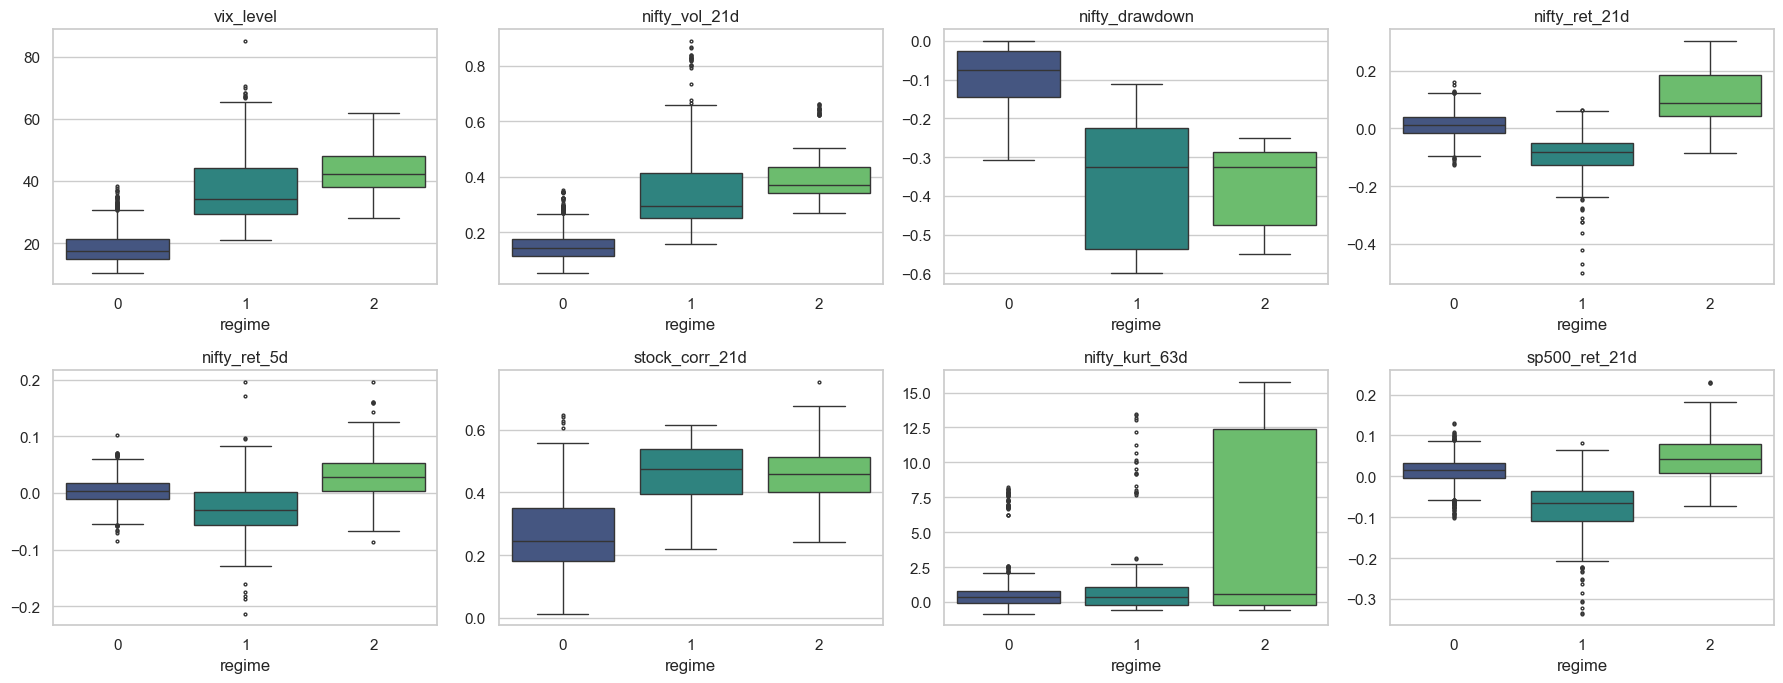

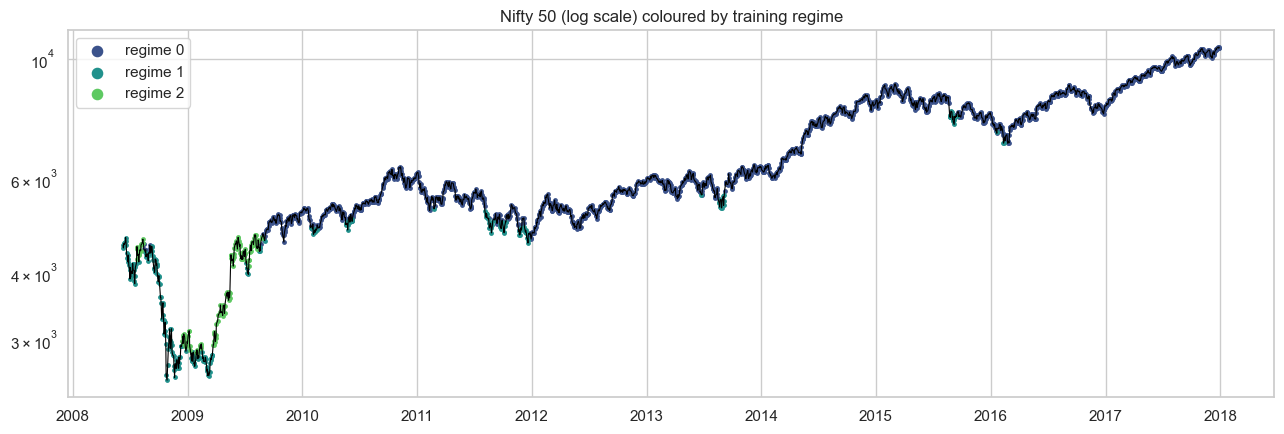

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
show = ["vix_level", "nifty_vol_21d", "nifty_drawdown", "nifty_ret_21d", "nifty_ret_5d", "stock_corr_21d", "nifty_kurt_63d", "sp500_ret_21d"]
pal = sns.color_palette("viridis", K_FINAL)
for ax_, c in zip(axes.ravel(), show):
    sns.boxplot(x=lab_train.values, y=train[c].values, palette=pal, ax=ax_, fliersize=2)
    ax_.set_title(c); ax_.set_xlabel("regime")
save_fig("profile_boxplots")

fig, ax = plt.subplots(figsize=(13, 4.5))
px = clean["nifty50"].reindex(train.index)
ax.plot(px.index, px.values, color="black", lw=.8)
for r in range(K_FINAL):
    m = lab_train == r
    ax.scatter(px.index[m], px.values[m], s=6, color=pal[r], label=f"regime {r}")
ax.set_yscale("log"); ax.set_title("Nifty 50 (log scale) coloured by training regime"); ax.legend(markerscale=3)
save_fig("train_timeline")

### Reading the profile (training data, actual numbers)

| | Regime 0 | Regime 1 | Regime 2 |
|---|---|---|---|
| Days | 1,957 (83.8%) | 244 (10.4%) | 135 (5.8%) |
| India VIX (mean) | 18.5 | 37.9 | 43.3 |
| Nifty 21-day volatility (annualised) | 15.0% | 35.8% | 40.9% |
| Drawdown from peak | -8.9% | -35.2% | -37.9% |
| 21-day return | +1.3% | **-9.6%** | **+10.6%** |
| 5-day return | +0.3% | -2.8% | +3.1% |
| Average stock correlation | 0.27 | 0.46 | 0.47 |
| 63-day excess kurtosis | 0.6 | 1.2 | **5.6** |
| S&P 500 21-day return | +1.4% | -8.1% | +4.8% |

**What separates the regimes**
- **Regime 0 vs the other two is a volatility and stress difference** (the PC1 axis): VIX 18 vs 38-43, volatility 15% vs 36-41%, drawdown -9% vs -35 to -38%, stock correlation 0.27 vs 0.46. This is a large, clean gap, and 84% of training days are in Regime 0, spread over every year from 2010 to 2017.
- **Regimes 1 and 2 are both stressed and are separated by direction** (the PC2 axis): Regime 1 days arrive after falling markets (21-day return -9.6%, S&P also falling, USD/INR rising), Regime 2 days after sharp rises (21-day return +10.6%, S&P rising) while the index is still about 38% below its peak and volatility is the highest in the table. Regime 2 also has much fatter tails (kurtosis 5.6), meaning large daily moves of both signs inside the window.
- **Realised volatility inside each regime** (std of the daily returns of all its days, annualised) is 15.2% / 42.0% / 39.2%. The ranking of the two stressed regimes depends on the measure: trailing 21-day volatility and VIX are higher in Regime 2, whereas the realised volatility of the days actually inside the regime is higher in Regime 1. The two stressed regimes are therefore **not** separable on volatility alone; they differ in direction and tails.
- In time, Regime 2 is entirely in **2008 and 2009** (135 of 135 days), mostly April to August 2009 (89 days), with relief rallies in mid-2008 and December 2008 to March 2009. Regime 1 is mostly September 2008 to March 2009 (103 days) and also contains August 2011, August 2013 and August 2015 (all 2008-2016, 244 days). A quick look at these dates is encouraging (the 2008 crash, the 2011 selloff, the 2013 taper episode and the August 2015 selloff all land in a stressed regime), but formal event validation is Phase 7.

**Names (based only on the numbers above)**
- **Regime 0: "Calm"**: lowest VIX, lowest volatility, shallow drawdown, low correlation, 84% of days.
- **Regime 1: "Stressed-Decline"**: VIX about 2x the calm level, volatility about 2.4x, drawdown of -35%, the 21-day return is clearly negative and global equities are also falling.
- **Regime 2: "Stressed-Rebound"**: the highest VIX and volatility, drawdown of about -38% (still deep), but a **positive** 21-day return of +10.6% and very high kurtosis. It is high-volatility *recovery from a crash*, not a calm recovery: the market is rising fast but is still in a stressed state.

**Important caveats on interpretation**
1. **The mean returns differ partly by construction.** The 1-day, 5-day and 21-day returns are *inputs* to the clustering, so a "negative-return" regime and a "positive-return" regime are guaranteed to exist if the data allow a split. This is why returns are descriptive here, not evidence of predictive value. The financially substantive facts are the volatility, VIX, drawdown and correlation.
2. **"Stressed-Rebound" has only 135 training days from one episode (2009).** The name describes that episode. In the test period it may capture different kinds of high-vol up-moves.
3. The name "Calm" covers a wide range (VIX 10 to 30), because everything not clearly stressed ends up there.

In [18]:
# Guard: each name must be supported by the profile numbers
p = prof.set_index(prof.index)
assert p["India VIX"].is_monotonic_increasing and p["21d vol (ann.)"].is_monotonic_increasing
assert p.loc[0, "India VIX"] < 25 and p.loc[0, "drawdown"] > -0.15                      # Calm: low VIX, shallow drawdown
assert p.loc[1, "India VIX"] > 30 and p.loc[1, "21d ret"] < -0.05 and p.loc[1, "S&P 21d ret"] < 0      # Stressed-Decline
assert p.loc[2, "India VIX"] > 30 and p.loc[2, "21d ret"] > 0.05 and p.loc[2, "drawdown"] < -0.25   # Stressed-Rebound
REGIME_NAMES = {0: "Calm", 1: "Stressed-Decline", 2: "Stressed-Rebound"}
print("Names validated against the profile:", REGIME_NAMES)

Names validated against the profile: {0: 'Calm', 1: 'Stressed-Decline', 2: 'Stressed-Rebound'}


## 10. Assigning the test data

**What:** the test features are standardised with the **training** `scaler`, projected with the **training** `pca`, and labelled with `km_final.predict()`. Nothing is refitted. Each test day is therefore assigned using only the training period's definition of the regimes; a day's label does not depend on any other test day, so the assignment cannot be affected by later data.

In [19]:
Z_test_check = scaler.transform(test)                                   # training scaler, transform only
X_test_check = pca.transform(Z_test_check)                              # training PCA, transform only
assert np.allclose(X_test_check, X_test.to_numpy())                    # identical to Section 5

raw_test = km_final.predict(X_test_check)                               # KMeans.predict, no refit
lab_test = pd.Series(raw_test, index=test.index, name="regime").map(relabel)
assert lab_test.index.equals(test.index) and lab_test.index.is_monotonic_increasing

share = pd.DataFrame({"train days": lab_train.value_counts().sort_index(), "train %": (lab_train.value_counts(normalize=True).sort_index() * 100).round(1),
                      "test days": lab_test.value_counts().sort_index(), "test %": (lab_test.value_counts(normalize=True).sort_index() * 100).round(1)}).fillna(0)
share.index = [f"{r}: {REGIME_NAMES[r]}" for r in share.index]
display(share)
display(pd.crosstab(lab_test.index.year, lab_test).rename(columns=REGIME_NAMES).T)

,train days,train %,test days,test %
0: Calm,1957,83.8,2083,95.9
1: Stressed-Decline,244,10.4,63,2.9
2: Stressed-Rebound,135,5.8,27,1.2


row_0,2018,2019,2020,2021,2022,2023,2024,2025,2026
regime,,,,,,,,,
Calm,245,241,188,248,232,245,245,247,192
Stressed-Decline,0,0,35,0,16,0,1,2,9
Stressed-Rebound,0,0,27,0,0,0,0,0,0


In [20]:
# Drift check: how far is each day from its assigned centre (in PC space)? Test days far outside the training range would be mis-assigned.
d_train = km_final.transform(Xtr).min(axis=1)
d_test = km_final.transform(X_test.to_numpy()).min(axis=1)
dist = pd.DataFrame({"train": np.percentile(d_train, [50, 90, 99, 100]), "test": np.percentile(d_test, [50, 90, 99, 100])}, index=["median", "90th pct", "99th pct", "max"])
display(dist.round(2))

# Test profile of the regimes, to see whether they still mean what they meant in training
prof_test = test[list(prof_cols)].assign(regime=lab_test).groupby("regime").mean().rename(columns=prof_cols)
prof_test.insert(0, "days", lab_test.value_counts().sort_index())
display(prof_test.T.round(3))

,train,test
median,2.73,2.71
90th pct,4.96,4.38
99th pct,8.44,7.65
max,17.42,17.73


regime,0,1,2
days,2083.000,63.000,27.000
1d ret,0.001,-0.010,0.009
5d ret,0.003,-0.036,0.033
21d ret,0.011,-0.143,0.090
21d vol (ann.),0.132,0.430,0.405
India VIX,15.929,40.042,34.519
drawdown,-0.048,-0.205,-0.217
stock corr,0.256,0.555,0.383
kurtosis 63d,1.345,3.912,3.837
skew 63d,-0.149,-1.060,-0.984


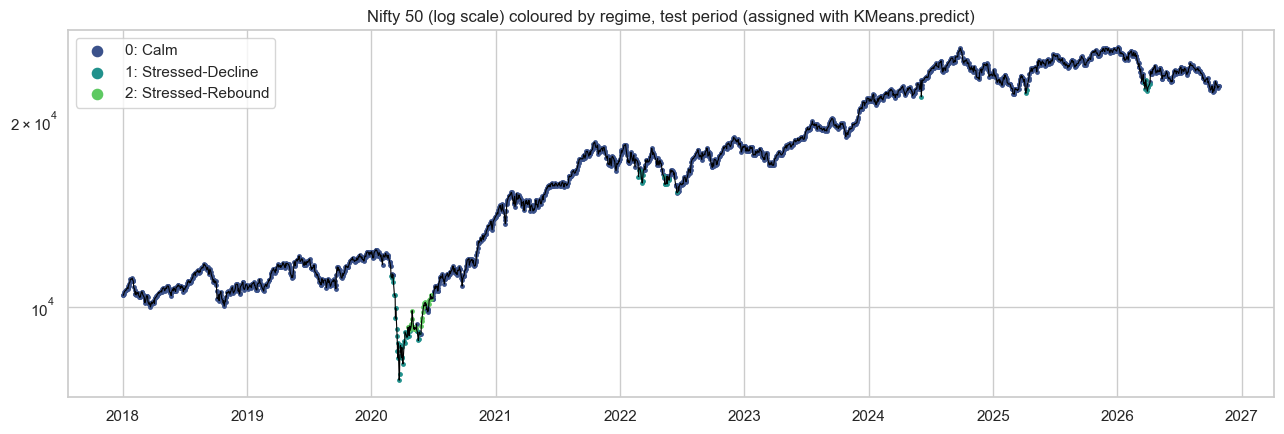

Regime counts, 15 Feb to 30 Jun 2020 (preview only; formal event validation is Phase 7):
regime
Stressed-Decline    35
Calm                27
Stressed-Rebound    27


In [21]:
fig, ax = plt.subplots(figsize=(13, 4.5))
pxt = clean["nifty50"].reindex(test.index)
ax.plot(pxt.index, pxt.values, color="black", lw=.8)
for r in range(K_FINAL):
    m = lab_test == r
    ax.scatter(pxt.index[m], pxt.values[m], s=6, color=pal[r], label=f"{r}: {REGIME_NAMES[r]}")
ax.set_yscale("log"); ax.set_title("Nifty 50 (log scale) coloured by regime, test period (assigned with KMeans.predict)"); ax.legend(markerscale=3)
save_fig("test_timeline")

covid = lab_test["2020-02-15":"2020-06-30"].map(REGIME_NAMES)
print("Regime counts, 15 Feb to 30 Jun 2020 (preview only; formal event validation is Phase 7):")
print(covid.value_counts().to_string())

**Interpretation:**
- **The test period is 95.9% Calm** (against 83.8% in training), consistent with the lower stress level seen in Section 3. Only **90 test days (4.1%)** fall in the two stressed regimes: 27 Stressed-Rebound and 63 Stressed-Decline, and they cluster in **2020 (27 + 35 days)**, with smaller numbers in 2022 (16 Stressed-Decline) and 2026 (9). All Stressed-Rebound test days are in 2020.
- **The distances to the assigned centre look similar in test and train** (median 2.7 in both, 99th percentile 7.7 in test vs 8.4 in train), so test days are not systematically outside the training cloud, despite the individual feature shifts noted in Section 4.
- **The stressed test regimes keep their direction but are milder than in training** (the profile above): in test, Stressed-Decline has a 21-day return of -14.3% and VIX 40 and Stressed-Rebound +9.0% with VIX 34.5, with drawdowns of about -21% (against -35% to -38% in training). The labels mean the same thing, but the severity is lower, which is expected for 2020 compared with 2008.
- **Important for Phases 8 and 9:** with 90 stressed test days from essentially one event, a classifier's stressed-regime recall and the backtest's difference to buy-and-hold will rest on very few independent episodes. The problem statement already lists this as a limitation, and the numbers confirm it. Phases 8 and 9 should report these counts next to the metrics.

## 11. Saving and validating the final output

**Columns saved in `data/processed/regimes.csv`** (one row per feature date, 4,509 rows):

| Column | Purpose |
|---|---|
| `Date` | index, same as `features.csv` |
| `regime` | integer label, 0 = lowest VIX (ordered by stress) |
| `regime_name` | name from Section 9 |
| `split` | `train` or `test`, carried over from Phase 5 |
| `pc1` ... `pc9` | PCA scores (Phase 7 plots, Phase 8 can reuse them) |
| `nifty_close`, `nifty_ret_1d` | Phase 9: the market return to trade, aligned to the same date (log return of day *t*) |
| `vix_level`, `nifty_drawdown` | Phase 7 tables and Phase 9 reporting |
| `risk_free_daily` | Phase 9: the cash-leg return from `macro.csv` |

**Timing rule for Phase 8 and 9:** `regime` on date *t* uses information up to the close of *t*. For prediction, the target is `regime` at *t+1*. For the backtest, the exposure for day *t+1* uses `regime` at *t* (`regime.shift(1)`). This file deliberately does *not* shift anything.

In [22]:
regimes = pd.concat([lab_train, lab_test]).sort_index().rename("regime").to_frame()
regimes["regime_name"] = regimes["regime"].map(REGIME_NAMES)
regimes["split"] = features["split"]
regimes = regimes.join(pd.concat([X_train, X_test]).rename(columns=str.lower))
regimes["nifty_close"] = clean["nifty50"].reindex(regimes.index)
regimes["nifty_ret_1d"] = features["nifty_ret_1d"]
regimes["vix_level"] = features["vix_level"]
regimes["nifty_drawdown"] = features["nifty_drawdown"]
regimes["risk_free_daily"] = macro["risk_free_daily"].reindex(regimes.index)

# ---- final checks ----
assert regimes["regime"].notna().all(), "missing regime"
assert regimes.index.is_unique, "duplicate dates"
assert regimes.index.is_monotonic_increasing, "not chronological"
assert regimes.index.equals(features.index), "dates differ from features.csv"
assert (regimes.loc[regimes["split"] == "train"].index <= TRAIN_END).all() and (regimes.loc[regimes["split"] == "test"].index > TRAIN_END).all()
assert regimes[["nifty_close", "nifty_ret_1d", "risk_free_daily"] + [c for c in regimes if c.startswith("pc")]].notna().all().all()
assert set(regimes["regime"]) == {0, 1, 2}
assert (regimes["nifty_ret_1d"] - np.log(regimes["nifty_close"]).diff()).abs().dropna().max() < 1e-4, "returns misaligned"

# the file must reproduce from the saved objects only (same fitted transformations for train and test)
joblib.dump(scaler, MODELS / "scaler.joblib"); joblib.dump(pca, MODELS / "pca.joblib"); joblib.dump(km_final, MODELS / "kmeans.joblib")
sc2, pca2, km2 = (joblib.load(MODELS / f"{n}.joblib") for n in ("scaler", "pca", "kmeans"))
re = pd.Series(km2.predict(pca2.transform(sc2.transform(features[FEATURE_COLS]))), index=features.index).map(relabel)
assert (re == regimes["regime"]).all(), "saved objects do not reproduce the labels"
# calling predict on the training rows reproduces the training labels (no refit anywhere)
assert (re.loc[train.index] == lab_train).all()

regimes.round(6).to_csv(PROC / "regimes.csv", index_label="Date")
meta = {"seed": SEED, "train_end": TRAIN_END, "n_components": N_COMP, "explained_variance": float(pca.explained_variance_ratio_.sum()),
        "k": K_FINAL, "feature_cols": FEATURE_COLS, "regime_names": REGIME_NAMES, "label_order": "0 = lowest mean India VIX in training",
        "relabel_from_kmeans_raw": relabel, "timing_note": "regime at t is known at close of t; shift by one day before using in forecasts or exposure rules"}
with open(PROC / "regime_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

saved = pd.read_csv(PROC / "regimes.csv", index_col="Date", parse_dates=True)
print("Saved", PROC / "regimes.csv", saved.shape)
print("All checks passed: no missing labels, no duplicate dates, chronological, dates match features.csv, objects reproduce labels.")
display(saved.head(3)); display(saved.tail(3))
display(saved.groupby(["split", "regime_name"]).size().unstack(fill_value=0))

Saved c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Project\Regime-Aware-Adaptive-Trading-Risk-Management-System\data\processed\regimes.csv (4509, 17)
All checks passed: no missing labels, no duplicate dates, chronological, dates match features.csv, objects reproduce labels.


,regime,regime_name,split,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,nifty_close,nifty_ret_1d,vix_level,nifty_drawdown,risk_free_daily
Date,,,,,,,,,,,,,,,,,
2008-06-09,1,Stressed-Decline,train,3.999230,-2.400701,-2.326633,-1.468574,-2.397522,-0.221737,-1.506716,-0.111883,0.657177,4500.9502,-0.027793,32.43,-0.284183,0.000308
2008-06-10,1,Stressed-Decline,train,3.931403,-2.363249,-1.724242,-1.114303,-2.429661,-0.190572,-1.216558,-0.035608,1.136595,4449.7998,-0.011429,30.23,-0.292318,0.000308
2008-06-11,1,Stressed-Decline,train,3.535480,-1.263997,0.271316,-0.016420,-2.673291,-0.106532,-0.943881,0.572427,1.581736,4523.6001,0.016449,29.64,-0.280581,0.000308


,regime,regime_name,split,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,nifty_close,nifty_ret_1d,vix_level,nifty_drawdown,risk_free_daily
Date,,,,,,,,,,,,,,,,,
2026-10-23,0,Calm,test,0.594385,-0.595186,-2.185495,1.502706,-0.949879,-0.761546,-1.699974,0.951323,0.934108,22600.0000,-0.003871,16.86,-0.141616,0.000218
2026-10-26,0,Calm,test,0.492805,-0.460033,-1.804789,1.576572,-1.311222,-0.710504,-1.741149,1.574055,1.172350,22753.1992,0.006756,17.16,-0.135798,0.000218
2026-10-27,0,Calm,test,0.223247,-0.296746,-1.580687,1.506728,-1.377996,-0.683266,-1.657244,0.661007,1.020255,22749.7500,-0.000152,16.40,-0.135929,0.000218


regime_name,Calm,Stressed-Decline,Stressed-Rebound
split,,,
test,2083,63,27
train,1957,244,135


## Summary of methodological decisions

| Step | Decision | Alternatives considered | Reason |
|---|---|---|---|
| Split | 2008-06-09 to 2017-12-29 train / 2018-01-02 to 2026-10-27 test | Random split, k-fold | Overlapping rolling windows; must mimic real use (fit on the past only) |
| Scaling | `StandardScaler`, train-only | MinMax, Robust | MinMax is dominated by a few crisis days; Robust would shrink the crisis signal we want to keep |
| PCA | 9 components (85.6% variance) | 10-11 components (88-91%); no PCA | Redundant features; 8-11 components give the same clusters (Section 5); parsimony |
| Clustering | K-Means (`n_init=50`, seed 42) | DBSCAN, GMM | Needs `predict()` for new days; stable in PCA space; GMM kept as future work |
| Cross-check | Ward on **all** training days, dendrogram truncated for display only | Single/complete/average linkage; sampling | Same objective as K-Means; no chaining; n = 2,336 is cheap, so no sampling needed |
| k | **3** | 2 (best silhouette), 4, 5 | Silhouette falls from 0.46 to 0.23 at k = 4; k = 2 cannot separate falling from rebounding stress; k = 3 is robust to dropping the two unusual features |
| Names | Calm / Stressed-Decline / Stressed-Rebound | Predefined Calm/Panic/Recovery | Assigned after profiling and checked against the numbers; "Recovery" is not used because the regime is still high-volatility |
| Test | `scaler.transform`, `pca.transform`, `KMeans.predict` | Refit on all data | No leakage |

**Known weaknesses to report:** the two stressed regimes overlap (weak silhouette), Ward splits the stress arm differently, the stressed regimes come from one or two episodes (2008-09 for training, 2020 for test), the test period is 95.9% Calm, and regime returns are partly circular because returns are clustering inputs.